# Demo · registering a post-Xenium H&E in code (10x human liver cancer)
Instructor demo, after the Xenium Explorer part (`explorer_demo.md`). Everything comes from `prepare_liver.py`:
the whole-section registration (three attempts, scored against the 10x keypoint alignment) and a 1 mm crop saved as
SpatialData. The live step (section 3) registers the crop again with multispace in a few seconds.

In [1]:
import json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import spatialdata as sd, spatialdata_plot  # noqa: F401
import multispace as ms
from spatialdata.transformations import get_transformation, set_transformation, Identity
from IPython.display import Image, display
PREP = Path("liver_prepared")

## 1 · Whole section: three attempts, scored

In [2]:
reg = json.load(open(PREP / "registration.json"))
pd.DataFrame({k: {c: v[c] for c in ("median_um_vs_10x", "max_um_vs_10x", "r_he_dapi")} for k, v in reg.items()}).T
# r_he_dapi: correlation of H&E haematoxylin (colour deconvolution) with DAPI after warping: nuclei overlap -> high

,median_um_vs_10x,max_um_vs_10x,r_he_dapi
10x keypoints (Xenium Explorer),0.00,0.00,0.478
multispace default,3324.93,8931.38,-0.017
multispace pre_rotation='auto',49.83,133.08,0.204
multispace + tile refinement,1.64,2.07,0.504


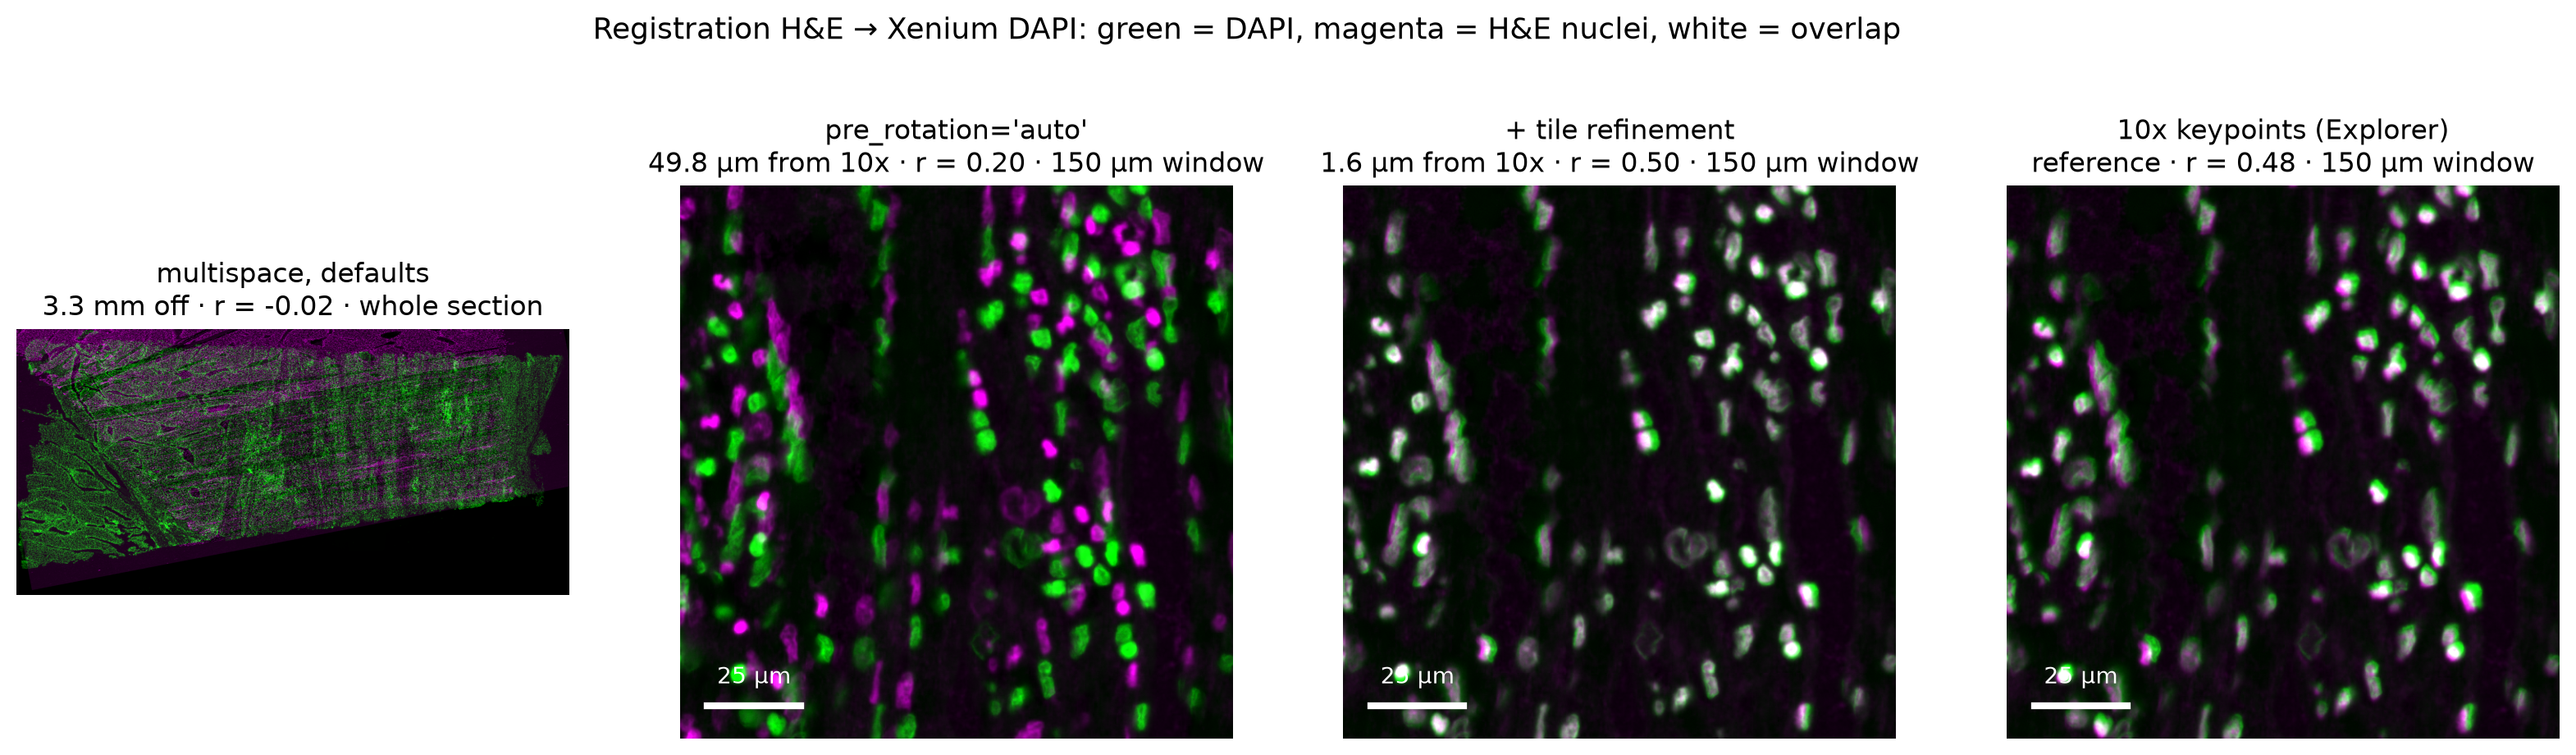

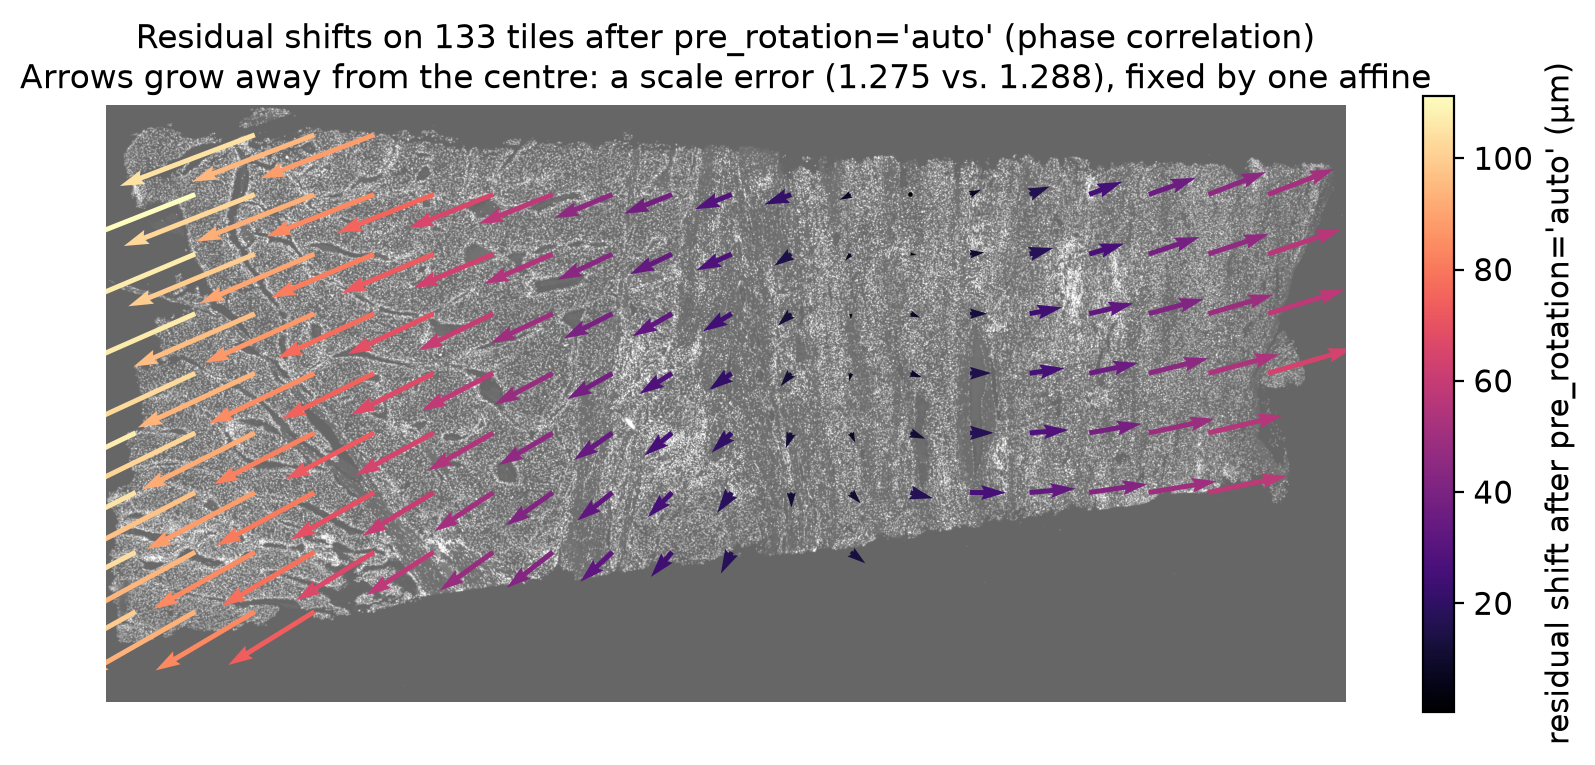

In [3]:
display(Image(PREP / "figures" / "L2_registration_attempts.png", width=1100))
display(Image(PREP / "figures" / "L3_refinement_shift_field.png", width=800))

**Why the default fails.** The H&E was scanned rotated by 90°. Intensity-based optimisation only searches near its
starting point, so it converges to a wrong local optimum and still returns a matrix: nothing crashes. `pre_rotation="auto"`
tries the four orientations first. The remaining ~1–2% scale error (L3) is then measured on tiles and removed with one affine.

## 2 · The 1 mm crop: one object, every layer

In [4]:
c = sd.read_zarr(PREP / "liver_crop.zarr")
c

SpatialData object, with associated Zarr store: /Users/k2481276/Documents/workshop/final/2_live_demo/liver_prepared/liver_crop.zarr
├── Images
│     ├── 'he': DataArray[cyx] (3, 3696, 3695)
│     └── 'morphology_focus': DataTree[cyx] (1, 4706, 4706), (1, 2354, 2354), (1, 1176, 1176), (1, 588, 588), (1, 295, 294)
├── Points
│     └── 'transcripts': DataFrame with shape: (580620, 6) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (4470, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (4392, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (4470, 474)
with coordinate systems:
    ▸ 'global', with elements:
        he (Images), morphology_focus (Images), transcripts (Points), cell_boundaries (Shapes), nucleus_boundaries (Shapes)

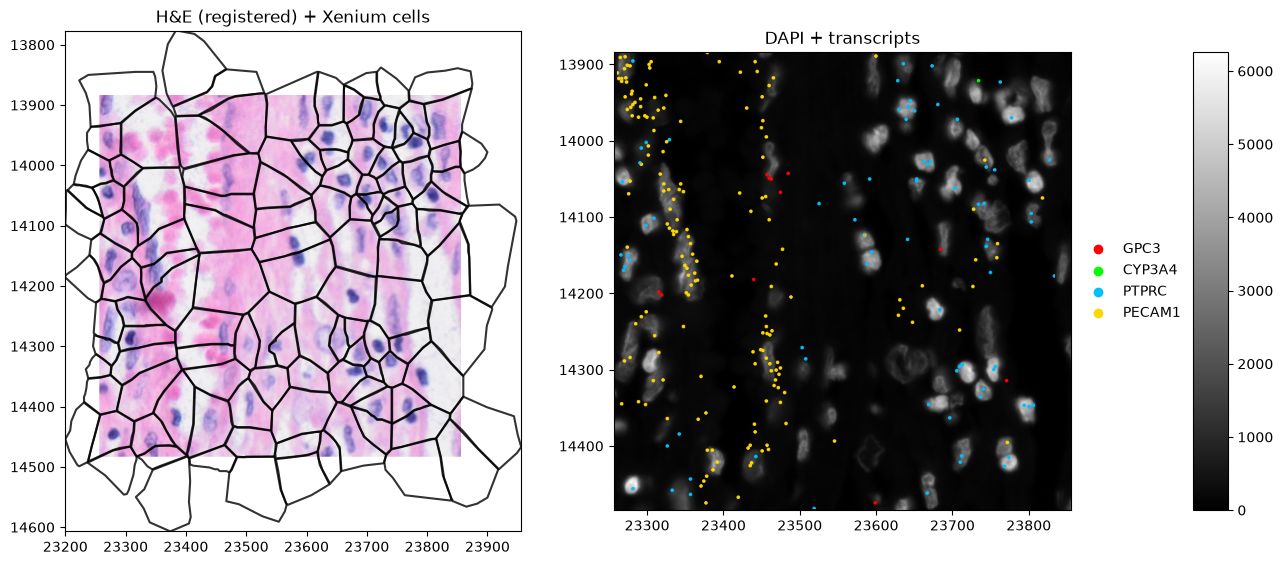

In [5]:
x0, y0, size = json.load(open(PREP / "crop.json"))["crop_xenium_px"]
w = 600; bx, by = x0 + size // 2 - w // 2, y0 + size // 2 - w // 2       # 130 µm window
win = sd.bounding_box_query(c, axes=("x", "y"), min_coordinate=[bx, by], max_coordinate=[bx + w, by + w],
                            target_coordinate_system="global")
fig, axs = plt.subplots(1, 2, figsize=(13, 6.5))
(win.pl.render_images("he").pl.render_shapes("cell_boundaries", fill_alpha=0, outline_alpha=0.8, outline_color="black")
    .pl.show(coordinate_systems="global", ax=axs[0], title="H&E (registered) + Xenium cells"))
(win.pl.render_images("morphology_focus", cmap="gray")
    .pl.render_points("transcripts", color="feature_name", groups=["GPC3", "CYP3A4", "PTPRC", "PECAM1"],
                      palette=["red", "lime", "deepskyblue", "gold"], size=3)
    .pl.show(coordinate_systems="global", ax=axs[1], title="DAPI + transcripts"))

## 3 · Live: register the crop with multispace
The crop's H&E is reset to its own pixel frame, then registered onto the DAPI crop. Compare with the transform from the
whole-section run (refined), which the crop came with.

In [6]:
M_ref = get_transformation(c.images["he"], to_coordinate_system="global").to_affine_matrix(("x", "y"), ("x", "y"))
live = sd.SpatialData(images={"morphology_focus": c.images["morphology_focus"], "he": c.images["he"]})
set_transformation(live.images["he"], {"he": Identity()}, set_all=True)
live.attrs["multispace"] = {"images": {"he": {"modality": "he"}}}
res = ms.register_image(live, "he", "morphology_focus", method="affine", pre_rotation="auto", max_side=1500)
M_live = get_transformation(live.images["he"], to_coordinate_system="global").to_affine_matrix(("x", "y"), ("x", "y"))
h, w_ = c.images["he"].shape[1:]
P = np.array([[0, 0, 1], [w_, 0, 1], [0, h, 1], [w_, h, 1], [w_ / 2, h / 2, 1]]).T
d_um = np.linalg.norm((M_live @ P - M_ref @ P)[:2], axis=0) * 0.2125
print("live crop registration vs whole-section refined transform: median %.1f µm, max %.1f µm" % (np.median(d_um), d_um.max()))

live crop registration vs whole-section refined transform: median 0.5 µm, max 0.8 µm


**Questions.** How would you know the registration is right if there were no 10x keypoints? (Score it: nuclei
overlap, a shift scan, a few trusted landmarks.) Why is a small crop easier to register than the whole section? What
changes when the target is not DAPI but a protein image (UnumLocalia, next)?